# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [15]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [16]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [17]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [18]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [19]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

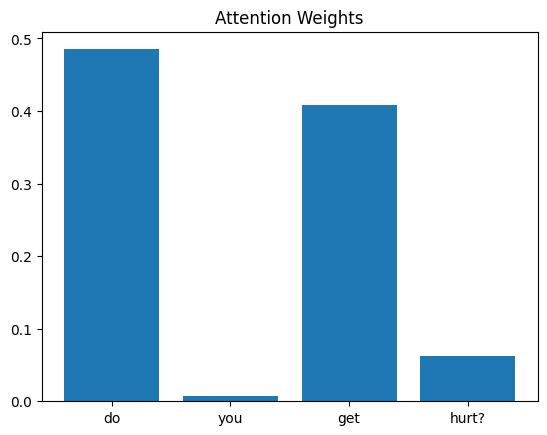

In [20]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question 0: do you get hurt?
Highest attention: do

Question 25: how long have you been around?
Highest attention: around

Question 19: which of us is younger?
Highest attention: is



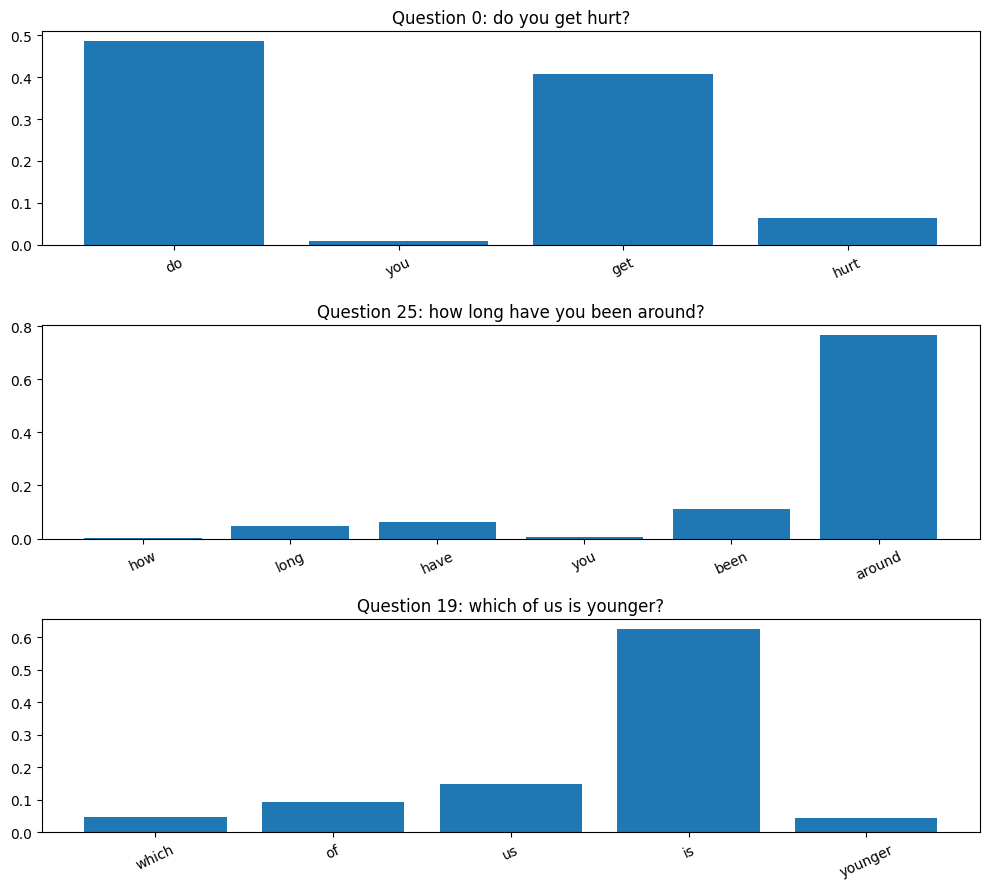

In [23]:
#Task 1
import numpy as np
import matplotlib.pyplot as plt
import torch

indices = [0, 25, 19]

model.eval()
fig, axes = plt.subplots(3, 1, figsize=(10, 9))

with torch.no_grad():
    _, all_weights = model(X[indices])

for ax, idx, attn in zip(axes, indices, all_weights):
    words = tokenized[idx]
    values = attn[:len(words)].tolist()

    top_word = words[np.argmax(values)]

    ax.bar(words, values)
    ax.set_title(f"Question {idx}: {df.iloc[idx]['question']}")
    ax.tick_params(axis="x", rotation=25)

    print(f"Question {idx}: {df.iloc[idx]['question']}")
    print(f"Highest attention: {top_word}")
    print()

plt.tight_layout()
plt.show()


Answer:

Not necessarily. The words receiving the highest attention weights were do, around, and is. While around is related to the question's meaning, more meaningful words such as hurt and younger received relatively low attention. This shows that the model sometimes prioritizes grammatical words over important keywords.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: do you get hurt?
Highest attention: do

Question: do you ever get hurt?
Highest attention: do



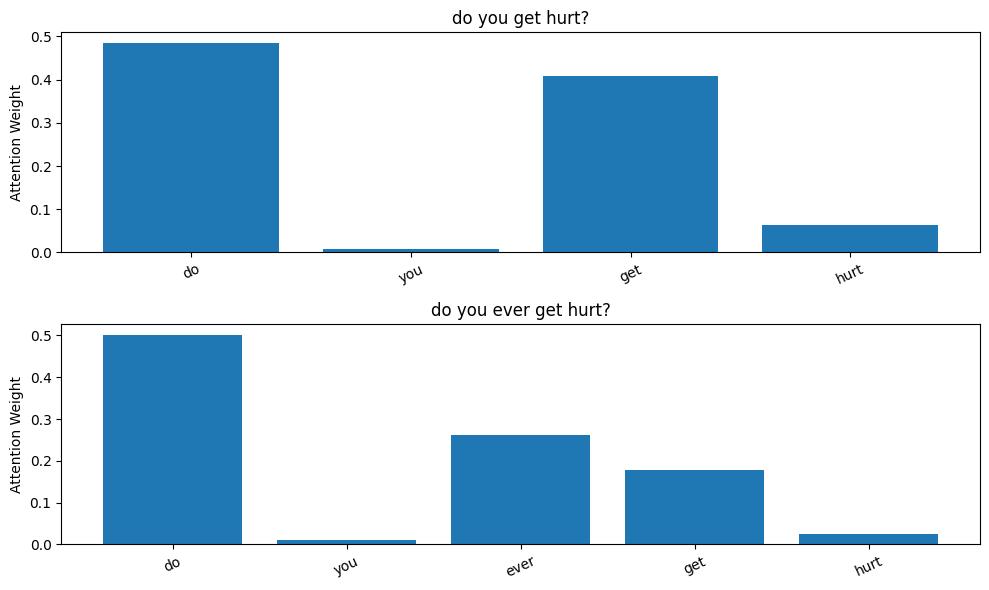

In [22]:
#Task 2
import numpy as np
import matplotlib.pyplot as plt
import torch
import re

def clean_words(s):
    return re.findall(r"[a-z0-9']+", str(s).lower())

tokenized = [clean_words(q) for q in df["question"]]

indices = [0, 10]

model.eval()

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

with torch.no_grad():
    logits, attns = model(X[indices])

for ax, idx, attn, logit in zip(
    axes, indices, attns, logits
):
    words = tokenized[idx]
    values = attn[:len(words)].tolist()

    top_word = words[int(np.argmax(values))]

    ax.bar(words, values)
    ax.set_title(df.iloc[idx]["question"])
    ax.set_ylabel("Attention Weight")
    ax.tick_params(axis="x", rotation=25)

    print(f"Question: {df.iloc[idx]['question']}")
    print(f"Highest attention: {top_word}")
    print()

plt.tight_layout()
plt.show()


Answer:
Both questions carry the same meaning, and the attention weight for do was high in both cases. Nevertheless, attention weight changed after adding ever. Attention weight for get reduced, whereas ever got some attention. This indicates that even a slight change in the wording affects attention weights.